In [ ]:
Step 1 – Import Libraries और Dataset Load

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv(r"C:\Users\LENOVO\OneDrive\Desktop\inreship_task_of_company\drive-download-20261124T061413Z-1-001\Dataset.csv")
print(df.head(10))

  show_id     type                             title             director  \
0      s1    Movie              Dick Johnson Is Dead      Kirsten Johnson   
1      s3  TV Show                         Ganglands      Julien Leclercq   
2      s6  TV Show                     Midnight Mass        Mike Flanagan   
3     s14    Movie  Confessions of an Invisible Girl        Bruno Garotti   
4      s8    Movie                           Sankofa         Haile Gerima   
5      s9  TV Show     The Great British Baking Show      Andy Devonshire   
6     s10    Movie                      The Starling       Theodore Melfi   
7    s939    Movie   Motu Patlu in the Game of Zones          Suhas Kadav   
8     s13    Movie                      Je Suis Karl  Christian Schwochow   
9    s940    Movie          Motu Patlu in Wonderland          Suhas Kadav   

          country date_added  release_year rating   duration  \
0   United States  9/25/2021          2020  PG-13     90 min   
1          France  9/24/

In [ ]:
# step 2 Dataset का structure check 

In [4]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe(include="all"))

Shape: (8790, 10)

Columns: ['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Data Types:
show_id           str
type              str
title             str
director          str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str 

#task 1 – Netflix Data Cleaning & Preparation

In [5]:
#1.1 Missing Values Check

missing_values = df.isnull().sum()

print(missing_values)

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


In [6]:
for col in df.columns:
    blank_count = (
        df[col].astype("string").str.strip().eq("").sum()
    )
    print(col, ":", blank_count)

show_id : 0
type : 0
title : 0
director : 0
country : 0
date_added : 0
release_year : 0
rating : 0
duration : 0
listed_in : 0


In [ ]:
#1.2 Duplicate Records Remov

In [7]:
print("Before:", df.shape)

df = df.drop_duplicates()

print("After:", df.shape)

Before: (8790, 10)
After: (8790, 10)


In [ ]:
#1.3 Text Formatting Standardize

In [8]:
text_columns = [
    "type", "title", "director",
    "country", "rating", "listed_in"
]

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

df["type"] = df["type"].str.title()
df["country"] = df["country"].str.replace(
    r"\s+", " ", regex=True
)
df["rating"] = df["rating"].str.upper()

In [ ]:
#1.4 Not Given Values Handle

In [9]:
df["country"] = df["country"].replace(
    "Not Given", pd.NA
)

In [ ]:
#1.5 Date Column Convert

In [10]:
df["date_added"] = pd.to_datetime(
    df["date_added"],
    errors="coerce"
)

In [ ]:
#1.6 Cleaned Dataset Export

In [11]:
df.to_csv("Netflix_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
Task 2 – Content Type Analysis Dashboard

In [ ]:
#2.1 Cleaned Dataset Load

In [12]:
df = pd.read_csv("Netflix_Cleaned.csv")

print(df.head())

  show_id     type                             title         director  \
0      s1    Movie              Dick Johnson Is Dead  Kirsten Johnson   
1      s3  Tv Show                         Ganglands  Julien Leclercq   
2      s6  Tv Show                     Midnight Mass    Mike Flanagan   
3     s14    Movie  Confessions of an Invisible Girl    Bruno Garotti   
4      s8    Movie                           Sankofa     Haile Gerima   

         country  date_added  release_year rating  duration  \
0  United States  2021-09-25          2020  PG-13    90 min   
1         France  2021-09-24          2021  TV-MA  1 Season   
2  United States  2021-09-24          2021  TV-MA  1 Season   
3         Brazil  2021-09-22          2021  TV-PG    91 min   
4  United States  2021-09-24          1993  TV-MA   125 min   

                                           listed_in  
0                                      Documentaries  
1  Crime TV Shows, International TV Shows, TV Act...  
2                

In [ ]:
#2.2 Movies और TV Shows की Count

In [13]:
content_count = df["type"].value_counts()

print(content_count)

type
Movie      6126
Tv Show    2664
Name: count, dtype: int64


In [ ]:
#2.3 Bar Chart

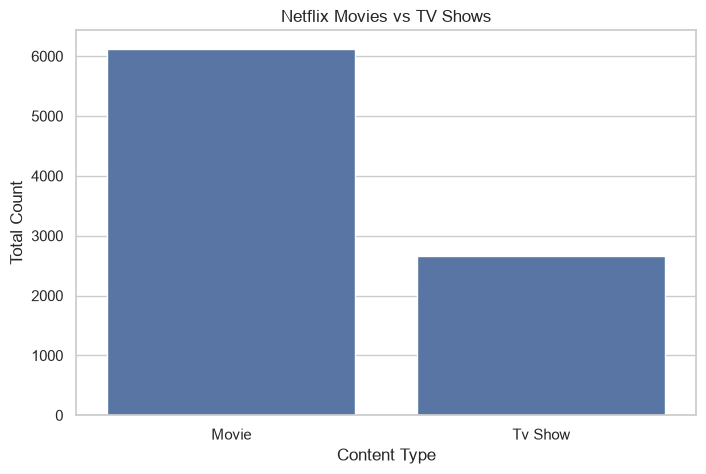

In [14]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="type"
)

plt.title("Netflix Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Total Count")

plt.show()

In [ ]:
#2.4 Pie Chart

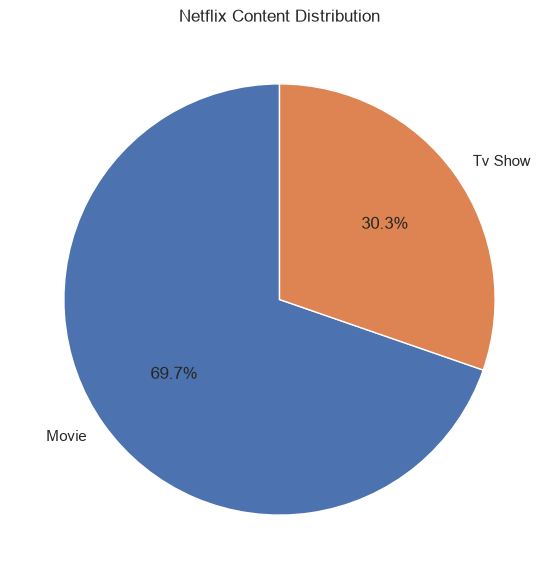

In [15]:
plt.figure(figsize=(7, 7))

plt.pie(
    content_count,
    labels=content_count.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Netflix Content Distribution")

plt.show()

In [ ]:
#2.5 Percentage Calculate

In [16]:
total = content_count.sum()

percentage = (content_count / total) * 100

print(percentage.round(2))

type
Movie      69.69
Tv Show    30.31
Name: count, dtype: float64


In [ ]:
#Task 3 – Country-Wise Netflix Content Analysis

In [ ]:
#3.1 Country Column Check

In [17]:
print(df["country"].head(10))

0     United States
1            France
2     United States
3            Brazil
4     United States
5    United Kingdom
6     United States
7             India
8           Germany
9             India
Name: country, dtype: str


In [ ]:
#3.2 Country Data Split

In [18]:
country_df = df.dropna(
    subset=["country"]
).copy()

country_df["country"] = country_df["country"].str.split(",")

country_df = country_df.explode("country")

country_df["country"] = country_df["country"].str.strip()

print(country_df[["title", "country"]].head(10))

                              title         country
0              Dick Johnson Is Dead   United States
1                         Ganglands          France
2                     Midnight Mass   United States
3  Confessions of an Invisible Girl          Brazil
4                           Sankofa   United States
5     The Great British Baking Show  United Kingdom
6                      The Starling   United States
7   Motu Patlu in the Game of Zones           India
8                      Je Suis Karl         Germany
9          Motu Patlu in Wonderland           India


In [ ]:
#3.3 Country-Wise Content Count

In [19]:
country_count = (
    country_df["country"]
    .value_counts()
    .reset_index()
)

country_count.columns = [
    "Country", "Total_Content"
]

print(country_count.head(10))

          Country  Total_Content
0   United States           3240
1           India           1057
2  United Kingdom            638
3        Pakistan            421
4          Canada            271
5           Japan            259
6     South Korea            214
7          France            213
8           Spain            182
9          Mexico            138


In [ ]:
#3.4 Top 10 Countries

In [20]:
top_10 = country_count.head(10)

print(top_10)

          Country  Total_Content
0   United States           3240
1           India           1057
2  United Kingdom            638
3        Pakistan            421
4          Canada            271
5           Japan            259
6     South Korea            214
7          France            213
8           Spain            182
9          Mexico            138


In [ ]:
#3.5 Top 10 Countries का Bar Chart

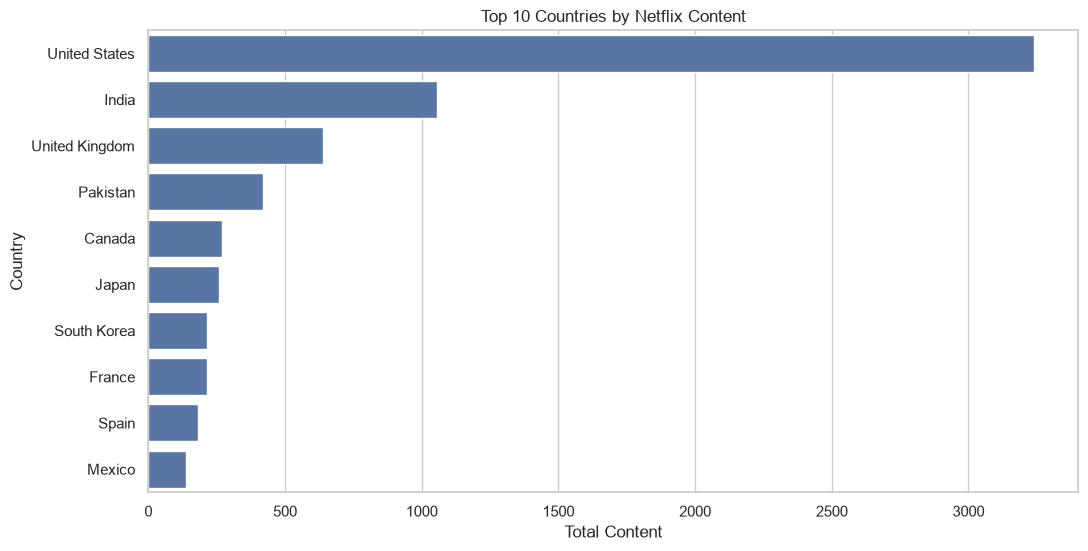

In [21]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10,
    x="Total_Content",
    y="Country"
)

plt.title("Top 10 Countries by Netflix Content")
plt.xlabel("Total Content")
plt.ylabel("Country")

plt.show()

In [ ]:
#3.6 Country और Content Type Comparison

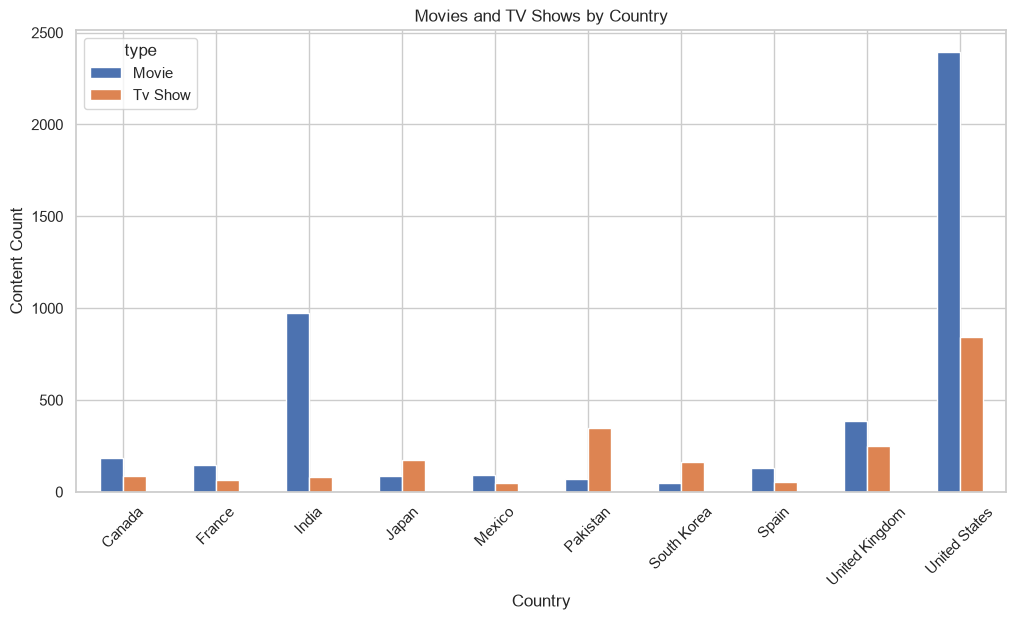

In [22]:
country_type = (
    country_df.groupby(["country", "type"])
    .size()
    .unstack(fill_value=0)
)

top_countries = country_count.head(10)["Country"]

country_type_top10 = country_type.loc[
    country_type.index.intersection(top_countries)
]

country_type_top10.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Movies and TV Shows by Country")
plt.xlabel("Country")
plt.ylabel("Content Count")
plt.xticks(rotation=45)

plt.show()

In [ ]:
#Task 4 – Trend Analysis by Release Year

In [23]:
year_count = (
    df.groupby("release_year")
    .size()
    .reset_index(name="Total_Content")
)

year_count = year_count.sort_values("release_year")

print(year_count.head(10))

   release_year  Total_Content
0          1925              1
1          1942              2
2          1943              3
3          1944              3
4          1945              4
5          1946              2
6          1947              1
7          1954              2
8          1955              3
9          1956              2


In [ ]:
#4.2 Top 10 Release Years

In [24]:
top_years = (
    year_count.sort_values(
        "Total_Content",
        ascending=False
    ).head(10)
)

print(top_years)

    release_year  Total_Content
70          2018           1146
69          2017           1030
71          2019           1030
72          2020            953
68          2016            901
73          2021            592
67          2015            555
66          2014            352
65          2013            286
64          2012            236


In [ ]:
# 4.3 Yearly Trend Line Chart

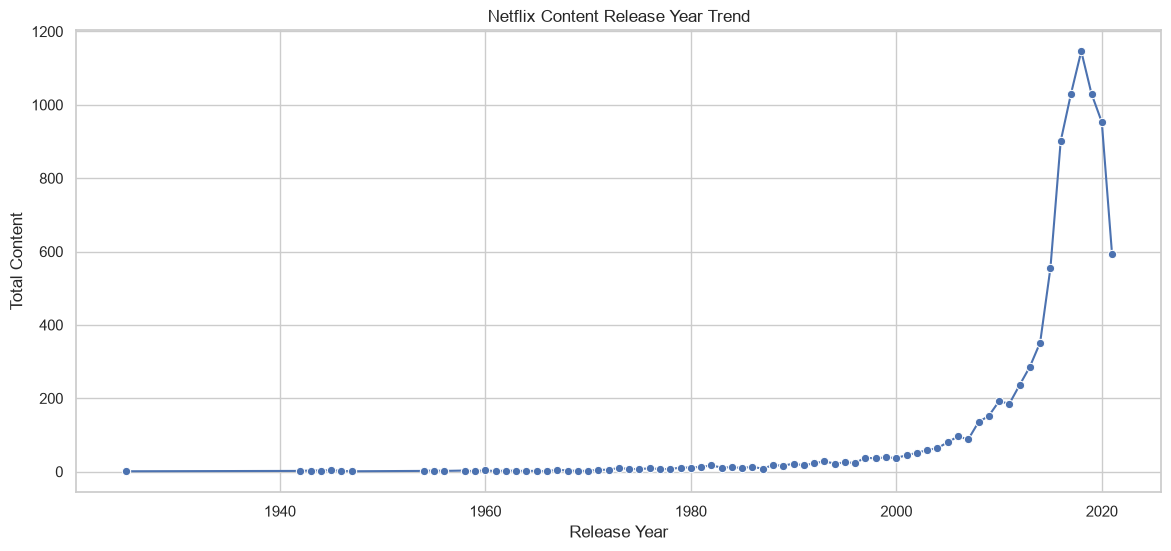

In [25]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=year_count,
    x="release_year",
    y="Total_Content",
    marker="o"
)

plt.title("Netflix Content Release Year Trend")
plt.xlabel("Release Year")
plt.ylabel("Total Content")

plt.show()

In [ ]:
#4.4 Movies और TV Shows की Yearly Comparison

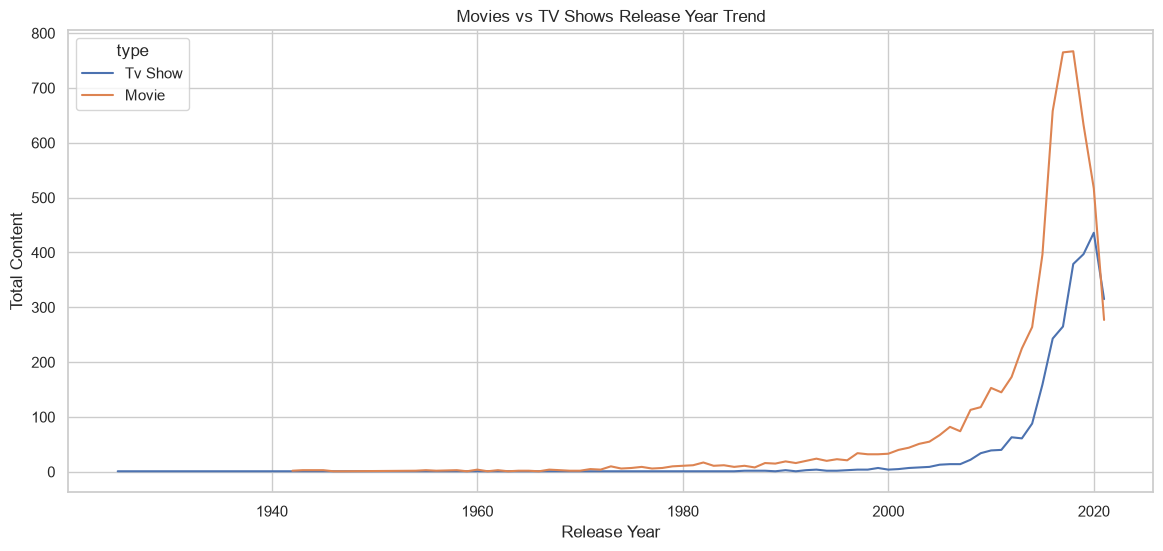

In [26]:
year_type = (
    df.groupby(["release_year", "type"])
    .size()
    .reset_index(name="Total_Content")
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=year_type,
    x="release_year",
    y="Total_Content",
    hue="type"
)

plt.title("Movies vs TV Shows Release Year Trend")
plt.xlabel("Release Year")
plt.ylabel("Total Content")

plt.show()

In [ ]:
#4.5 Year-over-Year Change

In [27]:
year_count["Previous_Year"] = (
    year_count["Total_Content"].shift(1)
)

year_count["YoY_Change"] = (
    year_count["Total_Content"]
    - year_count["Previous_Year"]
)

year_count["YoY_Growth_Percentage"] = (
    year_count["YoY_Change"]
    / year_count["Previous_Year"]
) * 100

print(year_count.tail(15))

    release_year  Total_Content  Previous_Year  YoY_Change  \
59          2007             88           96.0        -8.0   
60          2008            135           88.0        47.0   
61          2009            152          135.0        17.0   
62          2010            192          152.0        40.0   
63          2011            185          192.0        -7.0   
64          2012            236          185.0        51.0   
65          2013            286          236.0        50.0   
66          2014            352          286.0        66.0   
67          2015            555          352.0       203.0   
68          2016            901          555.0       346.0   
69          2017           1030          901.0       129.0   
70          2018           1146         1030.0       116.0   
71          2019           1030         1146.0      -116.0   
72          2020            953         1030.0       -77.0   
73          2021            592          953.0      -361.0   

    YoY

In [ ]:
#Task 5 – Content Rating & Genre Analysis

In [ ]:
#5.1 Rating Categories Count

In [28]:
rating_count = df["rating"].value_counts()

print(rating_count)

rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


In [ ]:
#5.2 Rating Distribution Chart

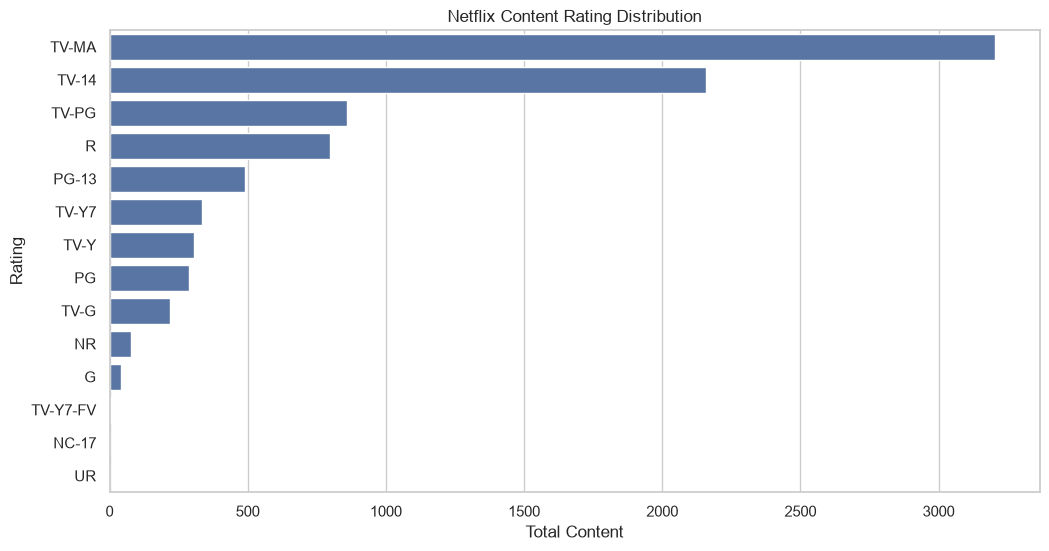

In [29]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="rating",
    order=df["rating"].value_counts().index
)

plt.title("Netflix Content Rating Distribution")
plt.xlabel("Total Content")
plt.ylabel("Rating")

plt.show()

In [ ]:
#5.3 Movies और TV Shows की Rating Comparison

In [30]:
rating_type = pd.crosstab(
    df["rating"],
    df["type"]
)

print(rating_type)

type      Movie  Tv Show
rating                  
G            41        0
NC-17         3        0
NR           75        4
PG          287        0
PG-13       490        0
R           797        2
TV-14      1427      730
TV-G        126       94
TV-MA      2062     1143
TV-PG       540      321
TV-Y        131      175
TV-Y7       139      194
TV-Y7-FV      5        1
UR            3        0


In [ ]:
#Chart:

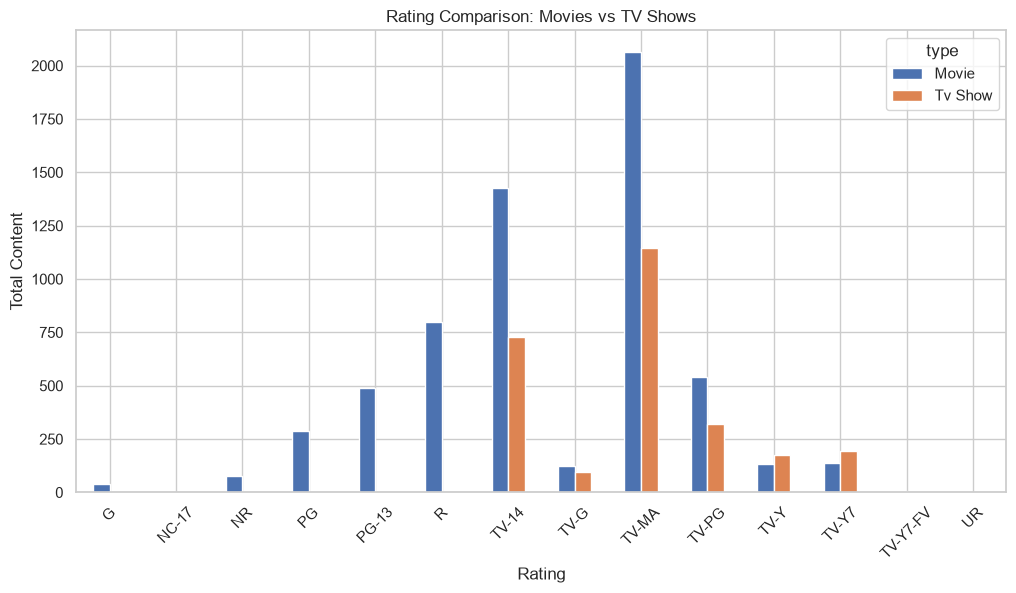

In [31]:
rating_type.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Rating Comparison: Movies vs TV Shows")
plt.xlabel("Rating")
plt.ylabel("Total Content")
plt.xticks(rotation=45)

plt.show()

In [ ]:
#5.4 Genre Analysis

In [32]:
genre_df = df.dropna(
    subset=["listed_in"]
).copy()

genre_df["listed_in"] = (
    genre_df["listed_in"].str.split(",")
)

genre_df = genre_df.explode("listed_in")

genre_df["listed_in"] = (
    genre_df["listed_in"].str.strip()
)

print(genre_df[["title", "listed_in"]].head(10))

                              title                 listed_in
0              Dick Johnson Is Dead             Documentaries
1                         Ganglands            Crime TV Shows
1                         Ganglands    International TV Shows
1                         Ganglands     TV Action & Adventure
2                     Midnight Mass                 TV Dramas
2                     Midnight Mass                 TV Horror
2                     Midnight Mass              TV Mysteries
3  Confessions of an Invisible Girl  Children & Family Movies
3  Confessions of an Invisible Girl                  Comedies
4                           Sankofa                    Dramas


In [ ]:
#5.5 Top 10 Genres

In [33]:
genre_count = (
    genre_df["listed_in"]
    .value_counts()
    .head(10)
)

print(genre_count)

listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


In [ ]:
# 5.6 Genre Bar Chart

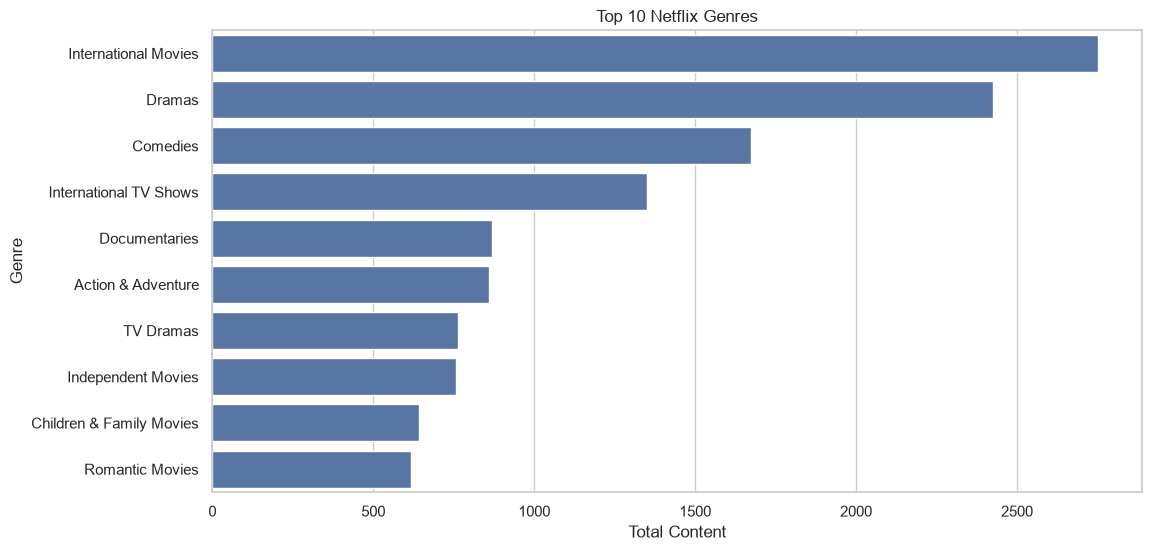

In [34]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_count.values,
    y=genre_count.index
)

plt.title("Top 10 Netflix Genres")
plt.xlabel("Total Content")
plt.ylabel("Genre")

plt.show()

In [ ]:
#5.7 Content Type के अनुसार Genre Comparison

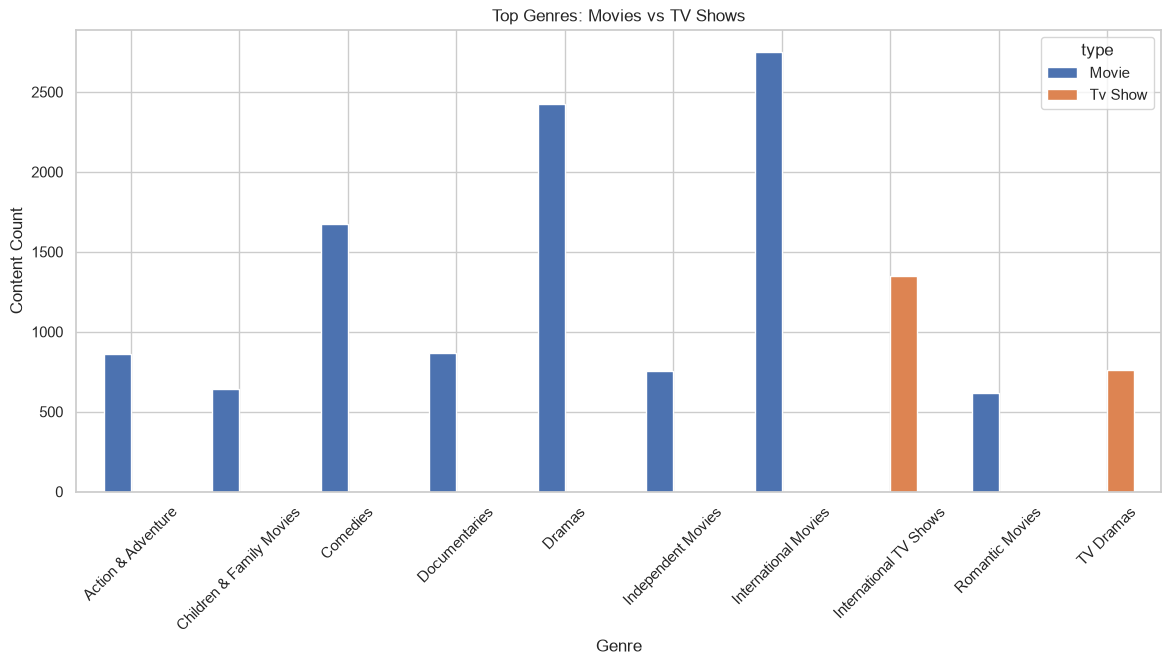

In [35]:
genre_type = (
    genre_df.groupby(["listed_in", "type"])
    .size()
    .unstack(fill_value=0)
)

top_genres = genre_count.index

genre_type_top10 = genre_type.loc[
    genre_type.index.intersection(top_genres)
]

genre_type_top10.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Top Genres: Movies vs TV Shows")
plt.xlabel("Genre")
plt.ylabel("Content Count")
plt.xticks(rotation=45)

plt.show()

In [ ]:
#task 6 – Netflix Business Insights Report

In [ ]:
#6.1 Important KPIs Calculate करना

In [36]:
total_content = len(df)

total_movies = (
    df["type"] == "Movie"
).sum()

total_tv_shows = (
    df["type"] == "TV Show"
).sum()

total_countries = (
    df["country"].dropna().str.split(",")
    .explode().str.strip().nunique()
)

total_genres = (
    df["listed_in"].dropna().str.split(",")
    .explode().str.strip().nunique()
)

print("Total Content:", total_content)
print("Total Movies:", total_movies)
print("Total TV Shows:", total_tv_shows)
print("Total Countries:", total_countries)
print("Total Genres:", total_genres)

Total Content: 8790
Total Movies: 6126
Total TV Shows: 0
Total Countries: 85
Total Genres: 42


In [ ]:
#6.2 KPI Dashboard बनाना

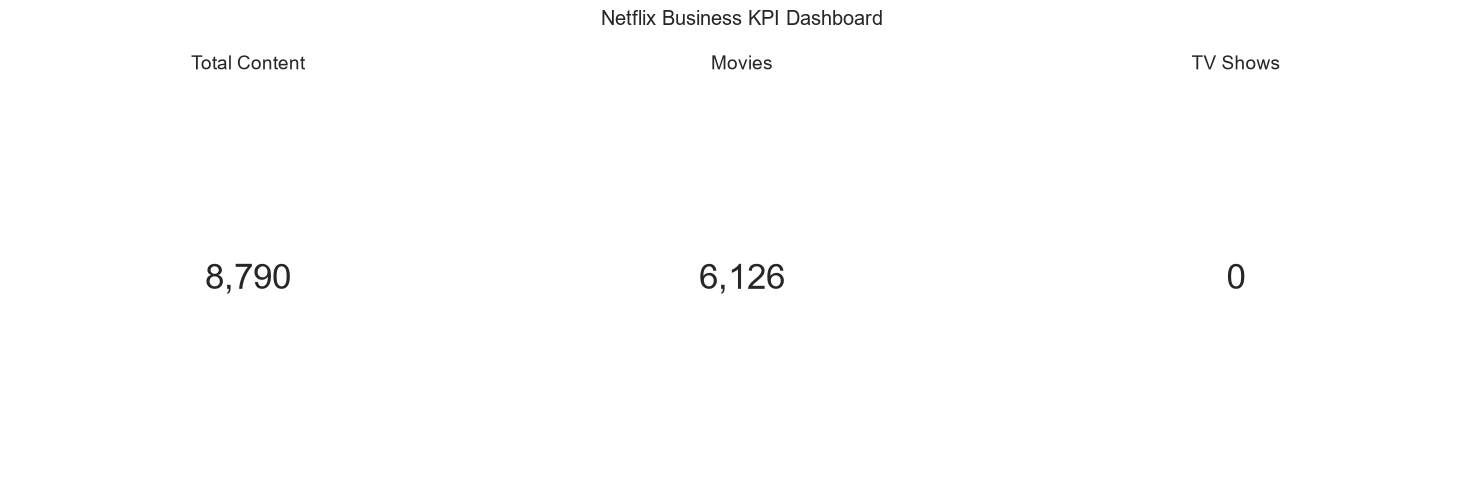

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

kpis = {
    "Total Content": total_content,
    "Movies": total_movies,
    "TV Shows": total_tv_shows
}

for ax, (title, value) in zip(axes, kpis.items()):
    ax.text(
        0.5, 0.5,
        f"{value:,}",
        fontsize=25,
        ha="center",
        va="center"
    )

    ax.set_title(title, fontsize=14)
    ax.axis("off")

plt.suptitle("Netflix Business KPI Dashboard")
plt.tight_layout()
plt.show()

In [ ]:
#6.3 Content Type Distribution

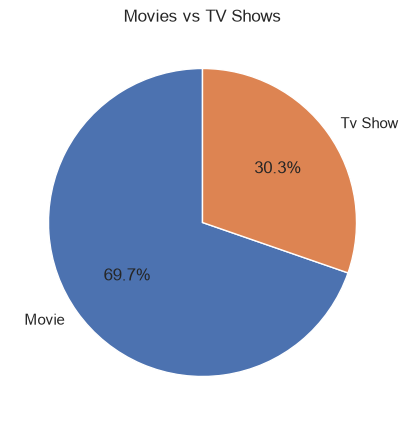

In [38]:
plt.figure(figsize=(7, 5))

df["type"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Movies vs TV Shows")
plt.ylabel("")

plt.show()

In [ ]:
#6.4 Top 10 Countries Dashboard

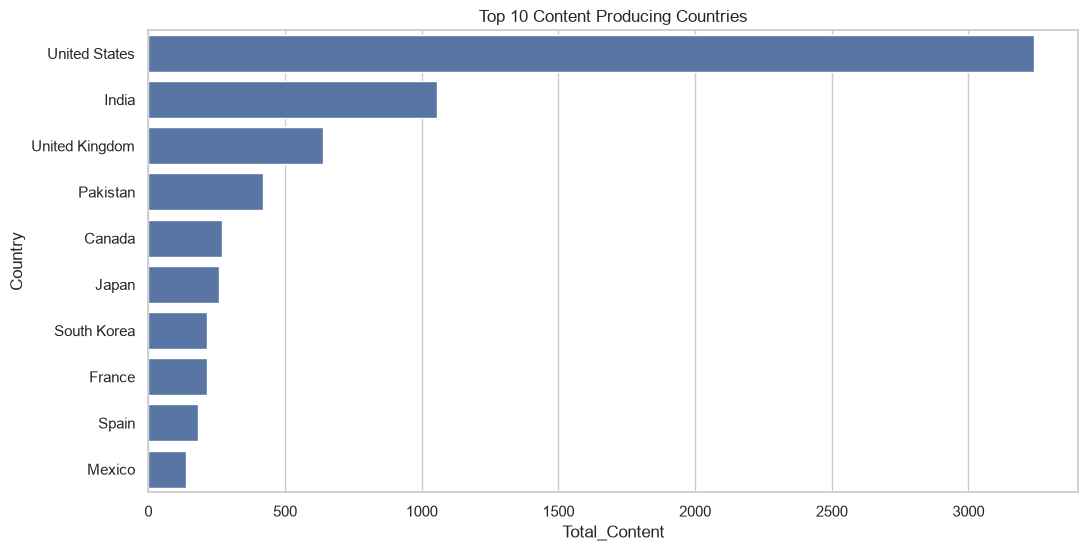

In [39]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=country_count.head(10),
    x="Total_Content",
    y="Country"
)

plt.title("Top 10 Content Producing Countries")
plt.show()

In [ ]:
#6.5 Top 10 Genres Dashboard

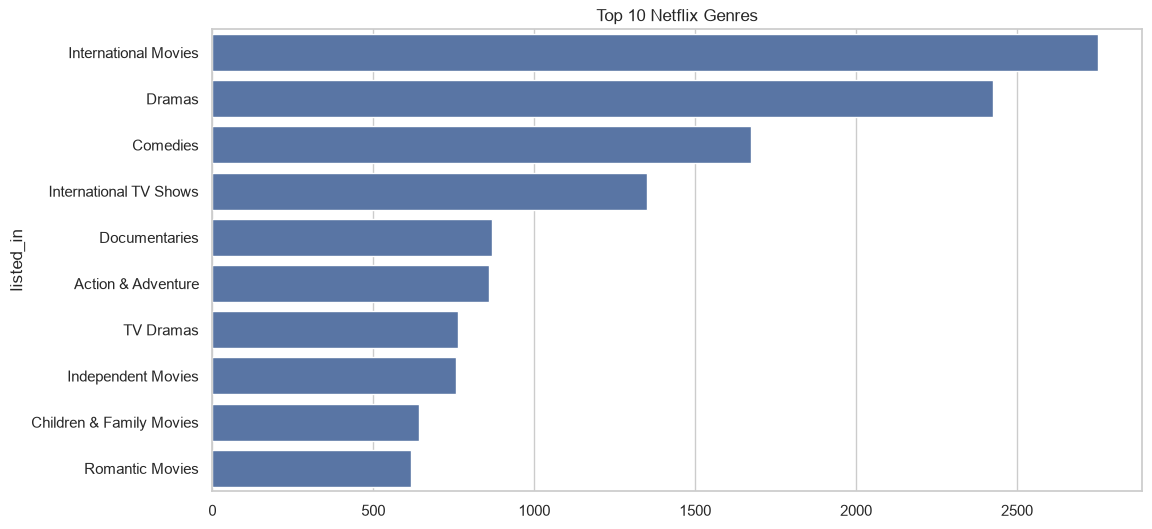

In [41]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_count.values,
    y=genre_count.index
)

plt.title("Top 10 Netflix Genres")
plt.show()

In [ ]:
# 6.6 Release Year Trend Dashboard

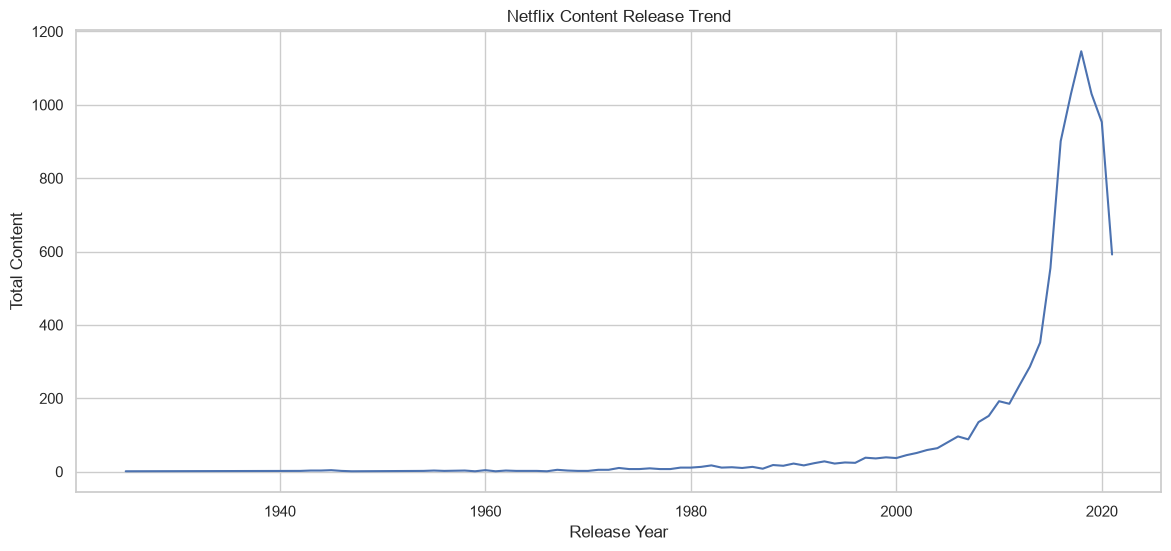

In [42]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=year_count,
    x="release_year",
    y="Total_Content"
)

plt.title("Netflix Content Release Trend")
plt.xlabel("Release Year")
plt.ylabel("Total Content")

plt.show()

In [ ]:
#6.7 Final Business Insights Automatically Generate

In [43]:
top_country = country_count.iloc[0]["Country"]
top_country_count = country_count.iloc[0]["Total_Content"]

top_genre = genre_count.index[0]
top_genre_count = genre_count.iloc[0]

top_rating = rating_count.index[0]
top_rating_count = rating_count.iloc[0]

movie_percentage = (
    total_movies / total_content
) * 100

tv_percentage = (
    total_tv_shows / total_content
) * 100

print("========== NETFLIX BUSINESS INSIGHTS ==========")

print(
    f"1. Total Netflix content records: {total_content:,}"
)

print(
    f"2. Movies represent {movie_percentage:.2f}% "
    "of the dataset."
)

print(
    f"3. TV Shows represent {tv_percentage:.2f}% "
    "of the dataset."
)

print(
    f"4. Top country by content count: "
    f"{top_country} ({top_country_count})"
)

print(
    f"5. Most common genre: "
    f"{top_genre} ({top_genre_count})"
)

print(
    f"6. Most common rating: "
    f"{top_rating} ({top_rating_count})"
)

========== NETFLIX BUSINESS INSIGHTS ==========
1. Total Netflix content records: 8,790
2. Movies represent 69.69% of the dataset.
3. TV Shows represent 0.00% of the dataset.
4. Top country by content count: United States (3240)
5. Most common genre: International Movies (2752)
6. Most common rating: TV-MA (3205)


In [ ]:
#6.8 Final Report Export

In [44]:
summary = pd.DataFrame({
    "KPI": [
        "Total Content",
        "Total Movies",
        "Total TV Shows",
        "Total Countries",
        "Total Genres",
        "Top Country",
        "Top Genre",
        "Top Rating"
    ],
    "Value": [
        total_content,
        total_movies,
        total_tv_shows,
        total_countries,
        total_genres,
        top_country,
        top_genre,
        top_rating
    ]
})

summary.to_csv(
    "Netflix_Business_Insights_Report.csv",
    index=False
)

print("Business Insights Report Exported!")

Business Insights Report Exported!


In [ ]:
#Task 5 (Advanced) – Content Rating & Genre Analysis
#PDF workflow: analyze rating categories; identify common genres; compare ratings across content types; create visualizations; present audience insights.

In [45]:
rating_counts = df["rating"].value_counts().rename_axis("Rating").reset_index(name="Title_Count")
display(rating_counts)

,Rating,Title_Count
0,TV-MA,3205
1,TV-14,2157
2,TV-PG,861
3,R,799
4,PG-13,490
5,TV-Y7,333
6,TV-Y,306
7,PG,287
8,TV-G,220
9,NR,79


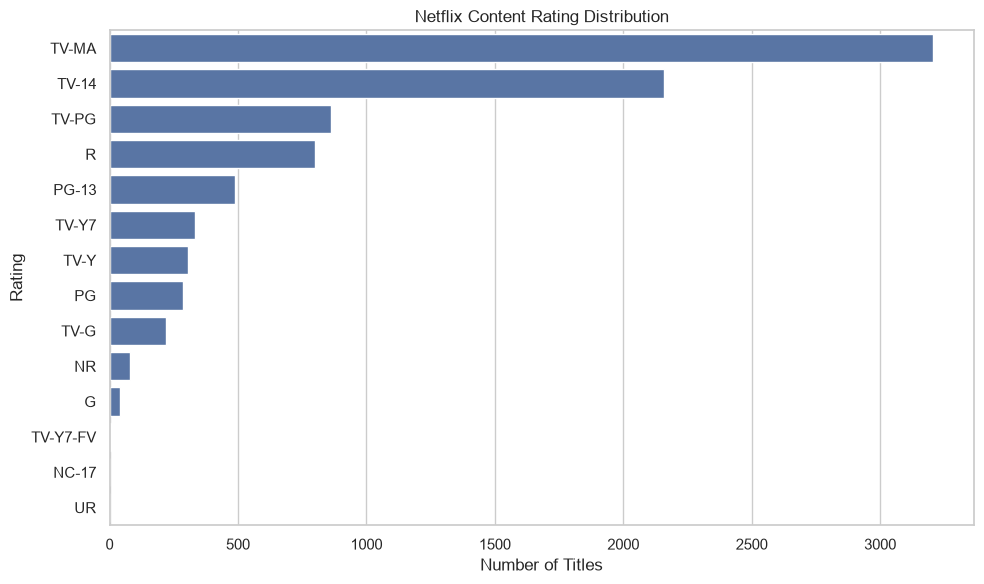

In [47]:
plt.figure(figsize=(10, 6))
sns.barplot(data=rating_counts, x="Title_Count", y="Rating")
plt.title("Netflix Content Rating Distribution")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")
plt.tight_layout()
plt.savefig("task5_rating_distribution.png", dpi=150)
plt.show()

type,Movie,Tv Show
rating,,
G,41,0
NC-17,3,0
NR,75,4
PG,287,0
PG-13,490,0
R,797,2
TV-14,1427,730
TV-G,126,94
TV-MA,2062,1143


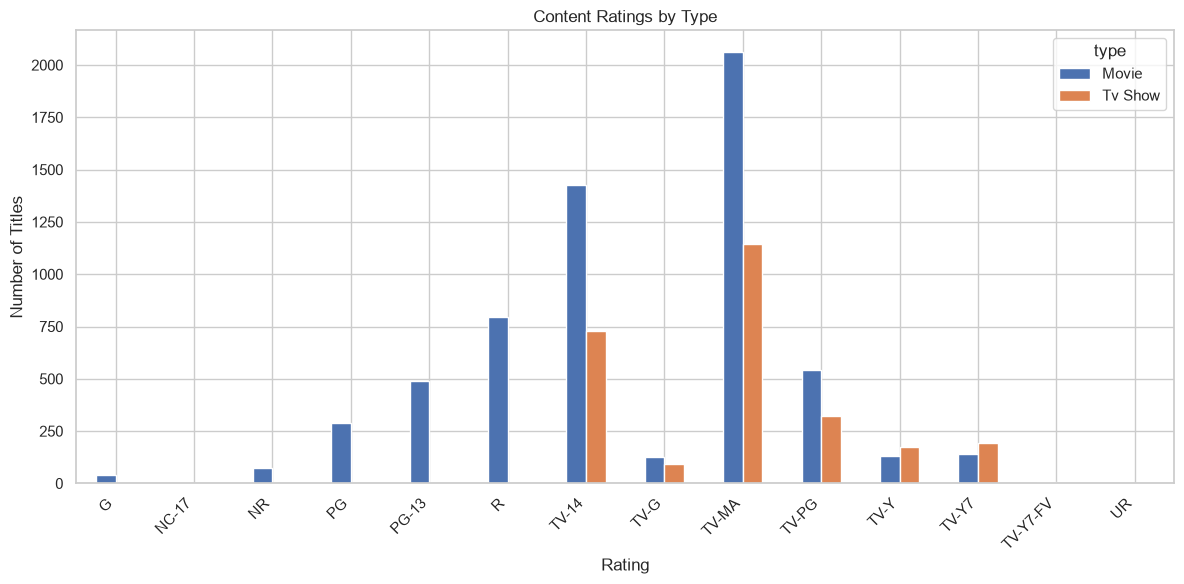

In [49]:
rating_type = pd.crosstab(df["rating"], df["type"])
display(rating_type)

rating_type.plot(kind="bar", figsize=(12, 6))
plt.title("Content Ratings by Type")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("task5_rating_by_type.png", dpi=150)
plt.show()

In [50]:
genre_df = df.dropna(subset=["listed_in"]).copy()
genre_df["listed_in"] = genre_df["listed_in"].str.split(",")
genre_df = genre_df.explode("listed_in")
genre_df["listed_in"] = genre_df["listed_in"].astype("string").str.strip()
genre_df = genre_df[genre_df["listed_in"].notna() & genre_df["listed_in"].ne("")]

genre_counts = (
    genre_df["listed_in"]
    .value_counts()
    .rename_axis("Genre")
    .reset_index(name="Title_Count")
)

display(genre_counts.head(15))

,Genre,Title_Count
0,International Movies,2752
1,Dramas,2426
2,Comedies,1674
3,International TV Shows,1349
4,Documentaries,869
5,Action & Adventure,859
6,TV Dramas,762
7,Independent Movies,756
8,Children & Family Movies,641
9,Romantic Movies,616


In [ ]:
# Task 6 (Advanced) – Netflix Business Insights Report
# PDF workflow: perform complete EDA; identify content trends and patterns; develop multiple visual dashboards; generate actionable insights; prepare a final report.

# The KPI values below are calculated from the cleaned dataset. Country and genre metrics are distinct counts or title-category records as labelled.

In [53]:
total_titles = len(df)
movies = int((df["type"] == "Movie").sum())
tv_shows = int((df["type"] == "TV Show").sum())
movie_pct = (movies / total_titles * 100) if total_titles else 0
tv_pct = (tv_shows / total_titles * 100) if total_titles else 0

unique_countries = country_df["country"].nunique() if not country_df.empty else 0
unique_genres = genre_df["listed_in"].nunique() if not genre_df.empty else 0

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total titles",
        "Movies",
        "TV Shows",
        "Movies percentage",
        "TV Shows percentage",
        "Distinct countries listed",
        "Distinct genres listed"
    ],
    "Value": [
        total_titles, movies, tv_shows,
        round(movie_pct, 2), round(tv_pct, 2),
        unique_countries, unique_genres
    ]
})
display(kpi_summary)

,Metric,Value
0,Total titles,8790.00
1,Movies,6126.00
2,TV Shows,0.00
3,Movies percentage,69.69
4,TV Shows percentage,0.00
5,Distinct countries listed,85.00
6,Distinct genres listed,42.00


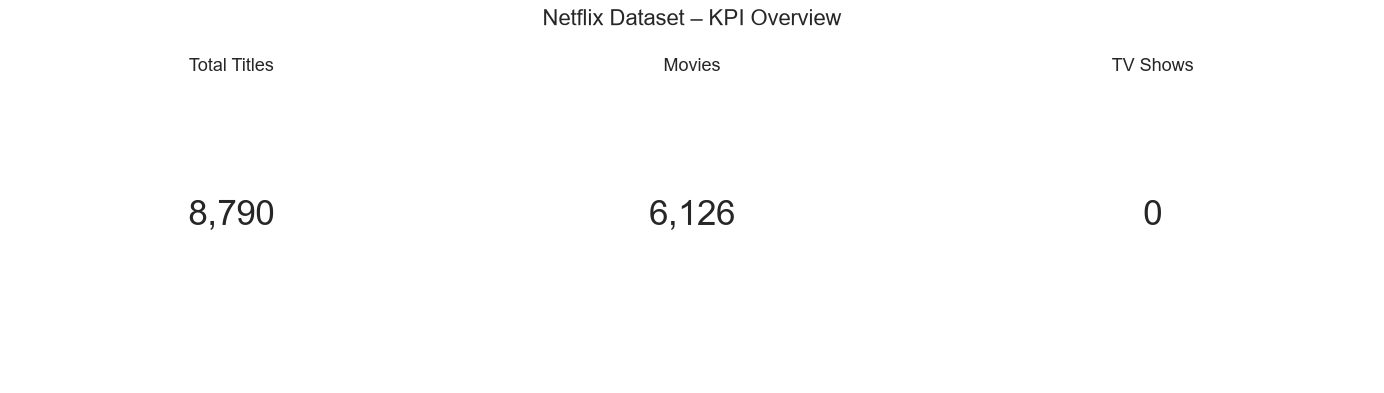

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
kpi_values = [
    ("Total Titles", total_titles),
    ("Movies", movies),
    ("TV Shows", tv_shows)
]

for ax, (label, value) in zip(axes, kpi_values):
    ax.text(0.5, 0.55, f"{value:,}", ha="center", va="center", fontsize=25)
    ax.set_title(label, fontsize=13)
    ax.axis("off")

fig.suptitle("Netflix Dataset – KPI Overview", fontsize=16)
plt.tight_layout()
plt.savefig("task6_kpi_overview.png", dpi=150)
plt.show()

In [ ]:
#Task 5 – Content Rating & Genre Analysis
#Step 3. Rating Categories Analysis

In [57]:
rating_count = df["rating"].value_counts()

print(rating_count)

rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


In [58]:
rating_df = (
    df["rating"]
    .value_counts()
    .reset_index()
)

rating_df.columns = ["Rating", "Total_Content"]

display(rating_df)

,Rating,Total_Content
0,TV-MA,3205
1,TV-14,2157
2,TV-PG,861
3,R,799
4,PG-13,490
5,TV-Y7,333
6,TV-Y,306
7,PG,287
8,TV-G,220
9,NR,79


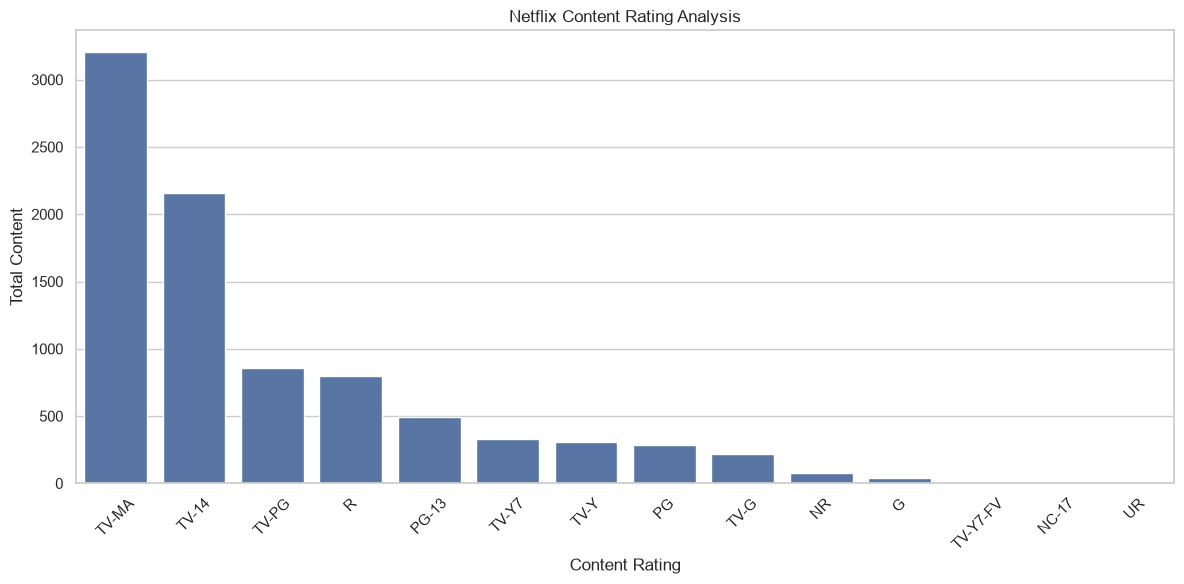

In [59]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=rating_df,
    x="Rating",
    y="Total_Content"
)

plt.title("Netflix Content Rating Analysis")
plt.xlabel("Content Rating")
plt.ylabel("Total Content")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [60]:
genre_df = df.dropna(
    subset=["listed_in"]
).copy()

genre_df["listed_in"] = (
    genre_df["listed_in"].str.split(",")
)

genre_df = genre_df.explode("listed_in")

genre_df["listed_in"] = (
    genre_df["listed_in"].str.strip()
)

display(genre_df[["title", "listed_in"]].head(10))

,title,listed_in
0,Dick Johnson Is Dead,Documentaries
1,Ganglands,Crime TV Shows
1,Ganglands,International TV Shows
1,Ganglands,TV Action & Adventure
2,Midnight Mass,TV Dramas
2,Midnight Mass,TV Horror
2,Midnight Mass,TV Mysteries
3,Confessions of an Invisible Girl,Children & Family Movies
3,Confessions of an Invisible Girl,Comedies
4,Sankofa,Dramas


In [ ]:
#Step 7. Top 10 Most Popular Genres

In [61]:
genre_count = (
    genre_df["listed_in"]
    .value_counts()
    .reset_index()
)

genre_count.columns = [
    "Genre",
    "Total_Content"
]

top_10_genres = genre_count.head(10)

display(top_10_genres)

,Genre,Total_Content
0,International Movies,2752
1,Dramas,2426
2,Comedies,1674
3,International TV Shows,1349
4,Documentaries,869
5,Action & Adventure,859
6,TV Dramas,762
7,Independent Movies,756
8,Children & Family Movies,641
9,Romantic Movies,616


In [ ]:
#Step 8. Top 10 Genres Visualization

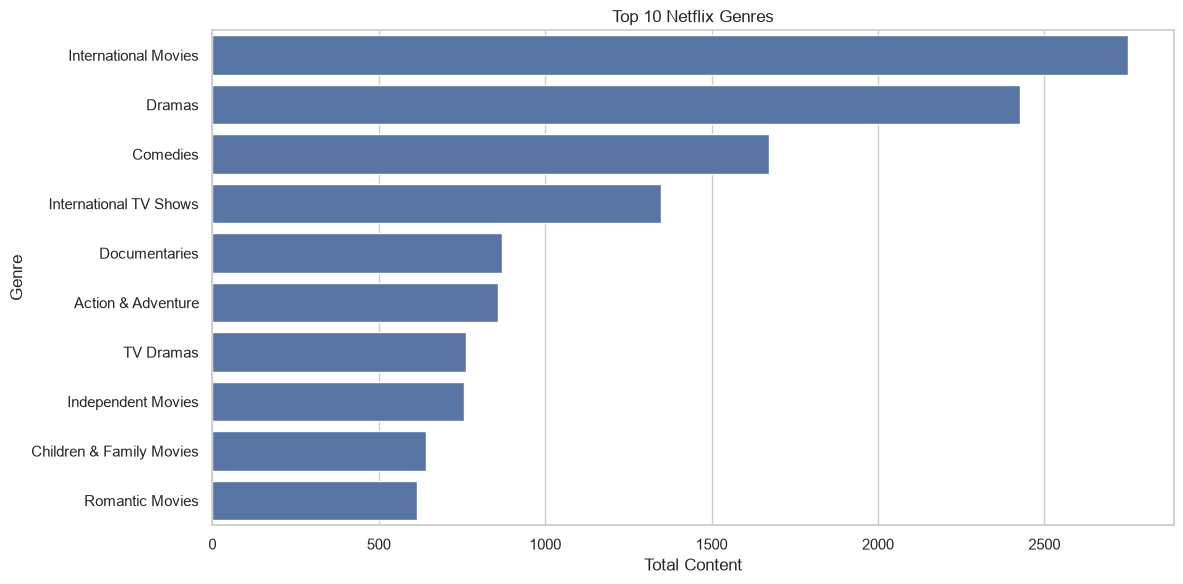

In [62]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_genres,
    x="Total_Content",
    y="Genre"
)

plt.title("Top 10 Netflix Genres")
plt.xlabel("Total Content")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

In [68]:
print("========== TASK 5: AUDIENCE INSIGHTS ==========")

print("Total Rating Categories:", df["rating"].nunique())

print(
    "Most Common Rating:",
    rating_df.iloc[0]["Rating"]
)

print(
    "Most Common Genre:",
    genre_count.iloc[0]["Genre"]
)

print(
    "Total Unique Genres:",
    genre_df["listed_in"].nunique()
)

print(
    "Most Common Rating Count:",
    rating_df.iloc[0]["Total_Content"]
)

print(
    "Most Common Genre Count:",
    genre_count.iloc[0]["Total_Content"]
)

========== TASK 5: AUDIENCE INSIGHTS ==========
Total Rating Categories: 14
Most Common Rating: TV-MA
Most Common Genre: International Movies
Total Unique Genres: 42
Most Common Rating Count: 3205
Most Common Genre Count: 2752


In [ ]:
#Task 6 – Netflix Business Insights Report

In [ ]:
#Step 1. Complete Exploratory Data Analysis (EDA)

In [69]:
print("========== DATASET OVERVIEW ==========")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

display(df.describe(include="all").T)

========== DATASET OVERVIEW ==========
Total Rows: 8790
Total Columns: 10

Column Names:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Data Types:
show_id           str
type              str
title             str
director          str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
dtype: object

Missing Values:
show_id           0
type              0
title             0
director          0
country         287
date_added        0
release_year      0
rating            0
duration          0
listed_in         0
dtype: int64

Duplicate Rows:
0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8790,8790,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8790,2,Movie,6126,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8790,8786,9-Feb,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,8790,4528,Not Given,2588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,8503,85,United States,3240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8790,1713,2020-01-01,110,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8790.0,NaN,NaN,NaN,2014.183163,8.825466,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8790,14,TV-MA,3205,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8790,220,1 Season,1791,NaN,NaN,NaN,NaN,NaN,NaN,NaN
listed_in,8790,513,"Dramas, International Movies",362,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
Calculate Business KPI
- Total Content
- Total Movies
- Total TV Shows
- Movies Percentage
- TV Shows Percentage
- Total Countries
- Total Genres

In [70]:
total_content = len(df)

total_movies = (
    df["type"] == "Movie"
).sum()

total_tv_shows = (
    df["type"] == "TV Show"
).sum()

movie_percentage = (
    total_movies / total_content
) * 100

tv_percentage = (
    total_tv_shows / total_content
) * 100

total_countries = (
    df["country"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .nunique()
)

total_genres = (
    df["listed_in"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .nunique()
)

print("Total Content:", total_content)
print("Total Movies:", total_movies)
print("Total TV Shows:", total_tv_shows)

print("Movies Percentage:", round(movie_percentage, 2))
print("TV Shows Percentage:", round(tv_percentage, 2))

print("Total Countries:", total_countries)
print("Total Genres:", total_genres)

Total Content: 8790
Total Movies: 6126
Total TV Shows: 0
Movies Percentage: 69.69
TV Shows Percentage: 0.0
Total Countries: 85
Total Genres: 42


In [ ]:
#Step 3. Create KPI Dashboard

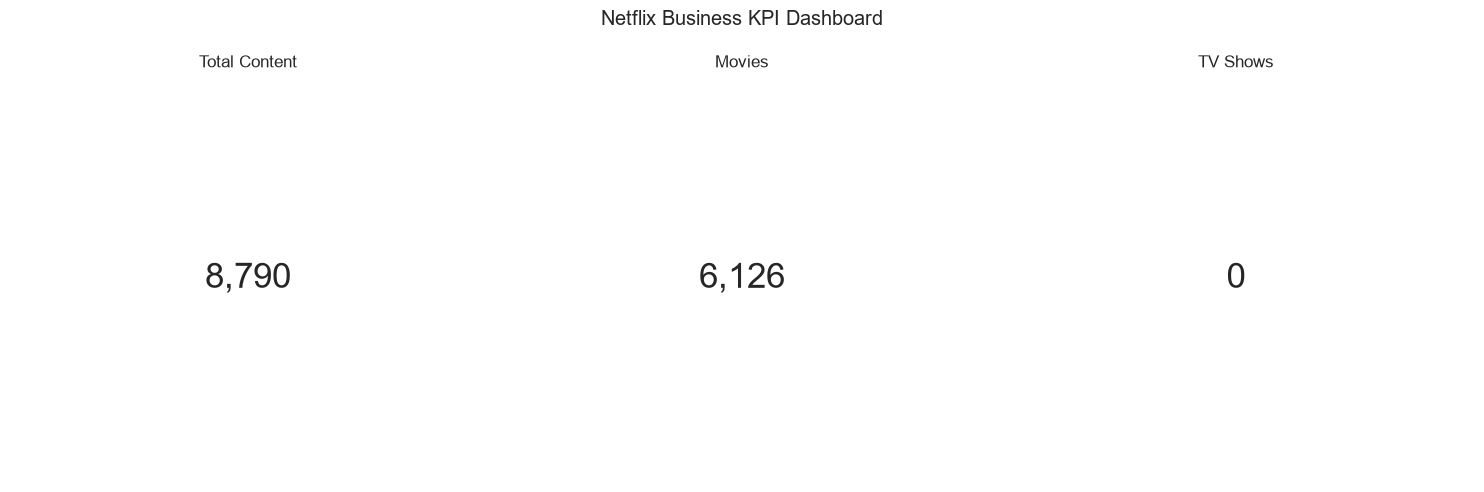

In [71]:
kpi_names = [
    "Total Content",
    "Movies",
    "TV Shows"
]

kpi_values = [
    total_content,
    total_movies,
    total_tv_shows
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

for ax, name, value in zip(
    axes,
    kpi_names,
    kpi_values
):
    ax.text(
        0.5,
        0.5,
        f"{value:,}",
        fontsize=25,
        ha="center",
        va="center"
    )

    ax.set_title(name)
    ax.axis("off")

plt.suptitle("Netflix Business KPI Dashboard")
plt.tight_layout()
plt.show()

In [ ]:
#Step 3: Data quality analysis

In [73]:
print("TOTAL ROWS:", df.shape[0])
print("TOTAL COLUMNS:", df.shape[1])

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nColumn Information:")
df.info()

TOTAL ROWS: 8790
TOTAL COLUMNS: 10

Missing Values:
show_id           0
type              0
title             0
director          0
country         287
date_added        0
release_year      0
rating            0
duration          0
listed_in         0
dtype: int64

Duplicate Records:
0

Column Information:
<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8503 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 1.6 MB


In [ ]:
#Step 4: Advanced KPI calculations

In [74]:
total_content = len(df)

movie_count = (df["type"] == "Movie").sum()
tv_count = (df["type"] == "TV Show").sum()

movie_percentage = (movie_count / total_content) * 100
tv_percentage = (tv_count / total_content) * 100

total_countries = df["country"].dropna().str.split(",").explode().str.strip().nunique()

total_genres = df["listed_in"].dropna().str.split(",").explode().str.strip().nunique()

print("========== NETFLIX BUSINESS KPIs ==========")

print("Total Content:", total_content)
print("Total Movies:", movie_count)
print("Total TV Shows:", tv_count)
print("Movie Percentage:", round(movie_percentage, 2), "%")
print("TV Show Percentage:", round(tv_percentage, 2), "%")
print("Total Countries:", total_countries)
print("Total Genres:", total_genres)

========== NETFLIX BUSINESS KPIs ==========
Total Content: 8790
Total Movies: 6126
Total TV Shows: 0
Movie Percentage: 69.69 %
TV Show Percentage: 0.0 %
Total Countries: 85
Total Genres: 42


In [ ]:
#Step 5: Advanced Dashboard – 4 Visualizations

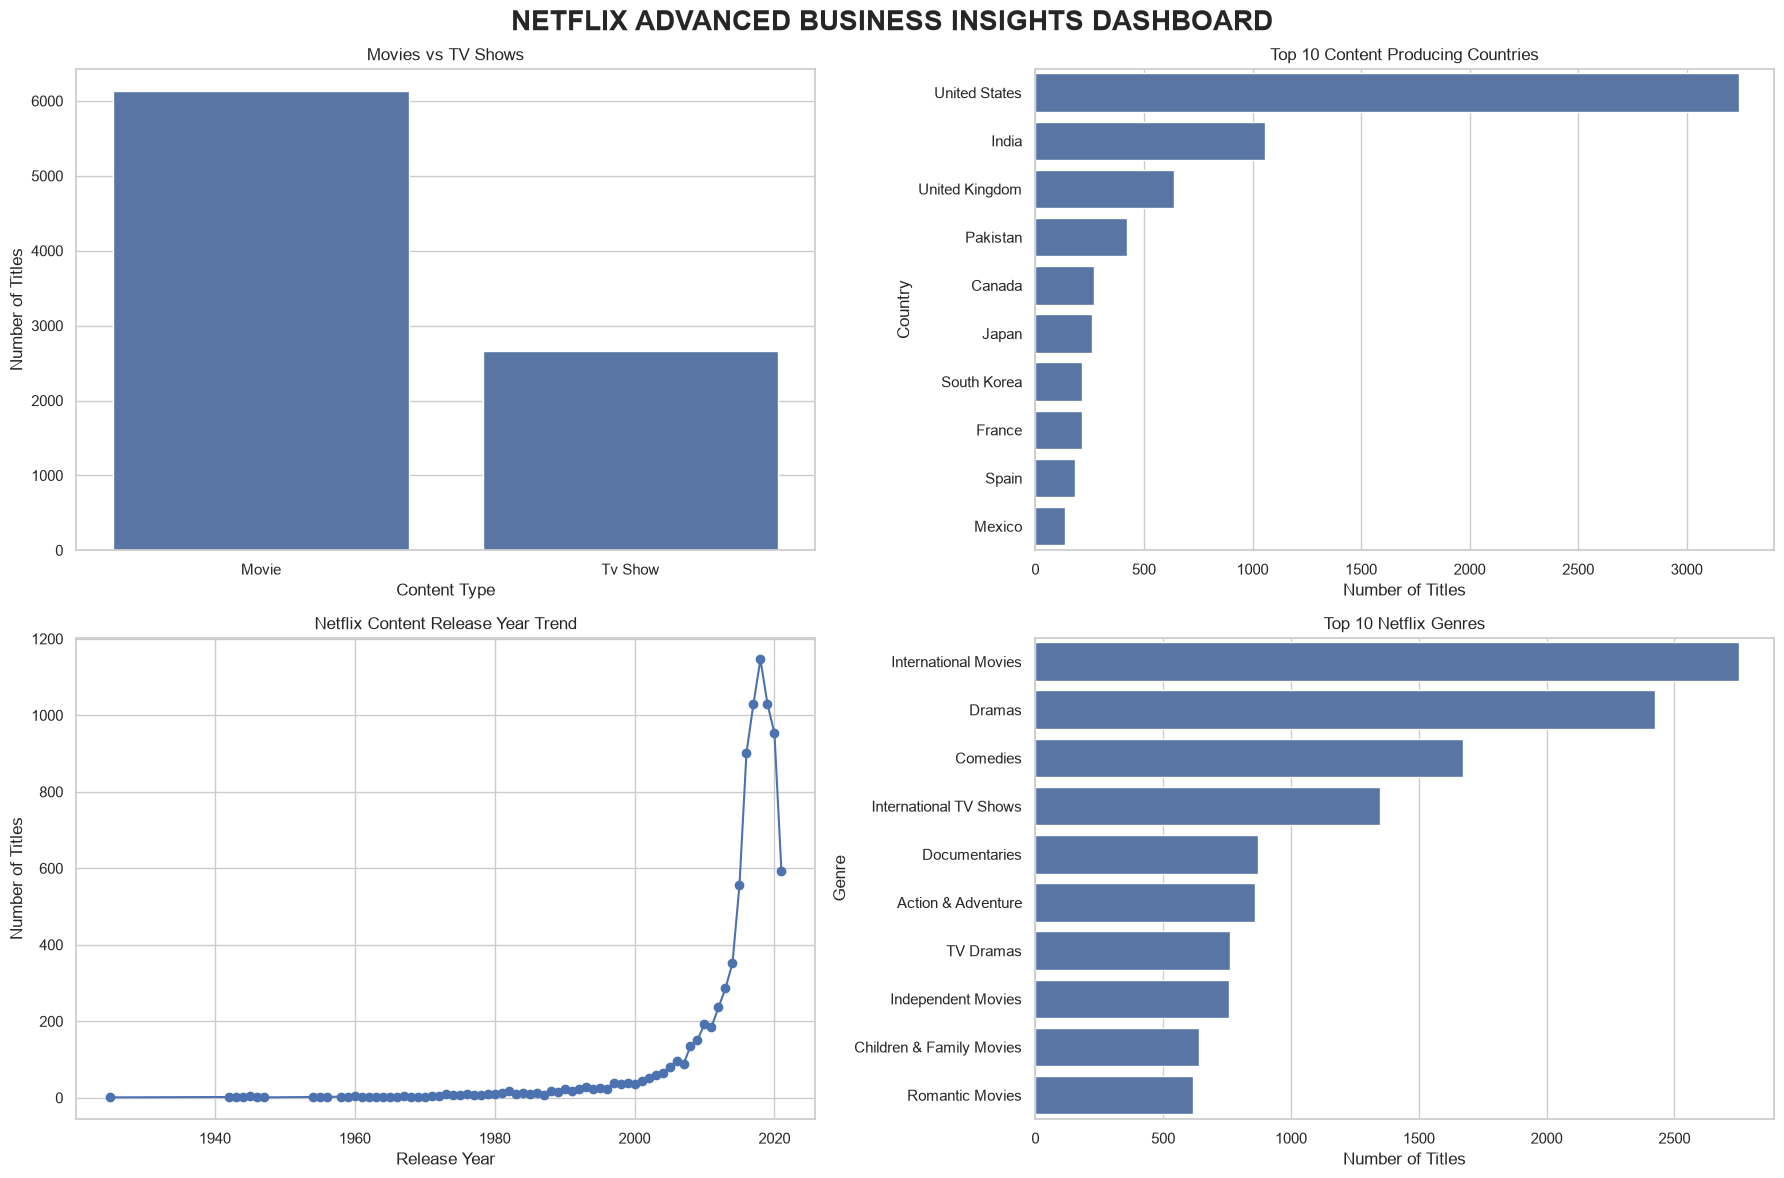

In [75]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

fig.suptitle(
    "NETFLIX ADVANCED BUSINESS INSIGHTS DASHBOARD",
    fontsize=20,
    fontweight="bold"
)

# Chart 1: Movies vs TV Shows
content_type = df["type"].value_counts()

sns.barplot(
    x=content_type.index,
    y=content_type.values,
    ax=axes[0, 0]
)

axes[0, 0].set_title("Movies vs TV Shows")
axes[0, 0].set_xlabel("Content Type")
axes[0, 0].set_ylabel("Number of Titles")

# Chart 2: Top 10 Countries
countries = (
    df["country"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

top_countries = countries.value_counts().head(10)

sns.barplot(
    x=top_countries.values,
    y=top_countries.index,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Top 10 Content Producing Countries")
axes[0, 1].set_xlabel("Number of Titles")
axes[0, 1].set_ylabel("Country")

# Chart 3: Release Year Trend
year_data = (
    df["release_year"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

axes[1, 0].plot(
    year_data.index,
    year_data.values,
    marker="o"
)

axes[1, 0].set_title("Netflix Content Release Year Trend")
axes[1, 0].set_xlabel("Release Year")
axes[1, 0].set_ylabel("Number of Titles")

# Chart 4: Top 10 Genres
genres = (
    df["listed_in"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

top_genres = genres.value_counts().head(10)

sns.barplot(
    x=top_genres.values,
    y=top_genres.index,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Top 10 Netflix Genres")
axes[1, 1].set_xlabel("Number of Titles")
axes[1, 1].set_ylabel("Genre")

plt.tight_layout()
plt.show()

In [ ]:
#Step 6: Interactive Plotly Dashboard

In [78]:
most_common_type = df["type"].mode()[0]
top_country = top_countries.index[0]
top_genre = top_genres.index[0]

oldest_year = int(df["release_year"].min())
latest_year = int(df["release_year"].max())

insights = [
    f"Netflix contains {total_content} total titles.",
    f"Movies account for {movie_percentage:.2f}% of the catalog.",
    f"TV Shows account for {tv_percentage:.2f}% of the catalog.",
    f"The most common content type is {most_common_type}.",
    f"The leading country by title count is {top_country}.",
    f"The most frequent genre is {top_genre}.",
    f"Release years range from {oldest_year} to {latest_year}."
]

print("========== NETFLIX BUSINESS INSIGHTS ==========")

for number, insight in enumerate(insights, start=1):
    print(f"{number}. {insight}")

========== NETFLIX BUSINESS INSIGHTS ==========
1. Netflix contains 8790 total titles.
2. Movies account for 69.69% of the catalog.
3. TV Shows account for 0.00% of the catalog.
4. The most common content type is Movie.
5. The leading country by title count is United States.
6. The most frequent genre is International Movies.
7. Release years range from 1925 to 2021.


In [ ]:
#Step 8: Export Reports into CSV

In [ ]:
#Step 6 – Advanced Interactive Dashboard

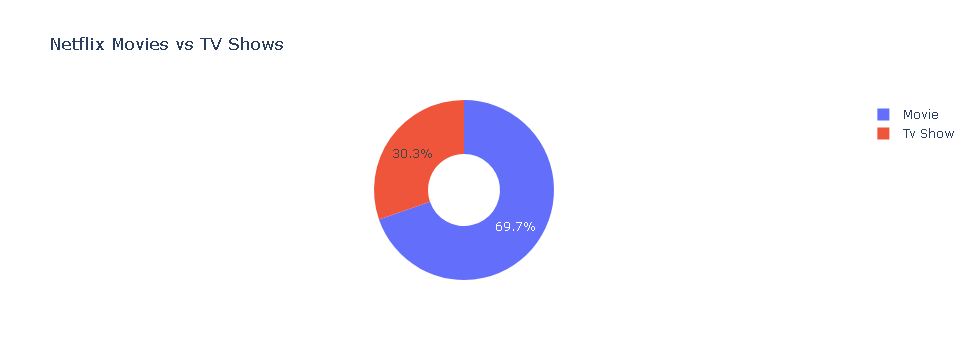

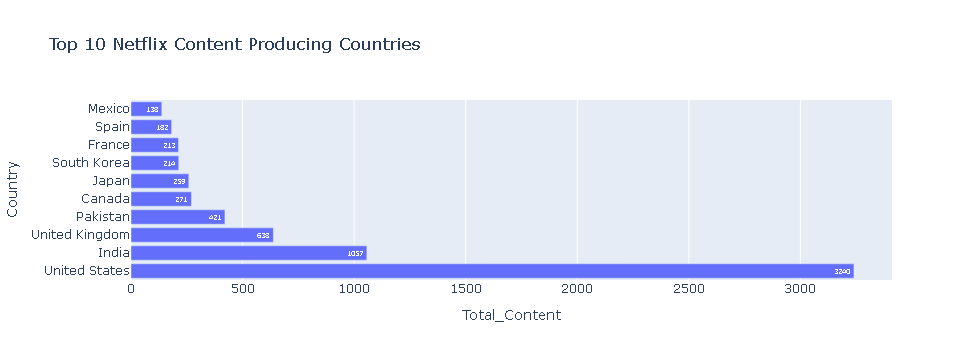

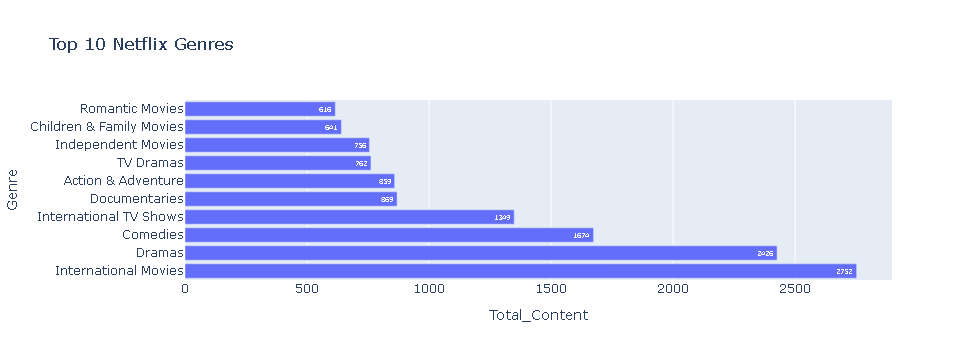

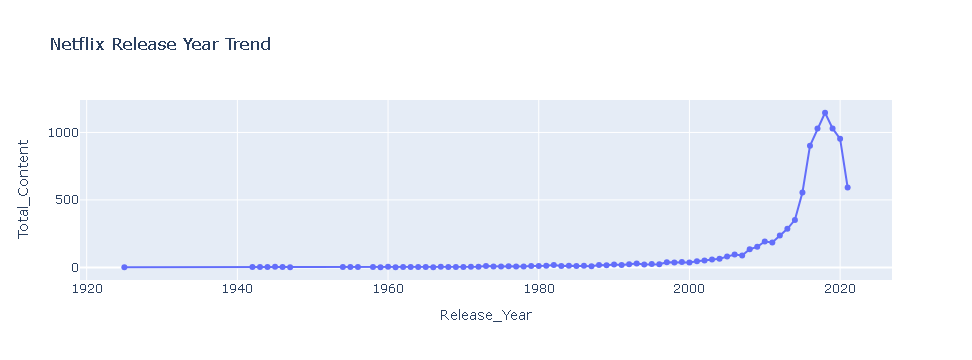

Step 6 Completed Successfully!


In [82]:
import pandas as pd
import numpy as np
import plotly.express as px
import os

# Load cleaned dataset
df = pd.read_csv("Netflix_Cleaned.csv")

# Check required columns
required_columns = ["type", "country", "listed_in", "release_year"]

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Column missing: {col}")

# Content Type Analysis
content_type = df["type"].value_counts().reset_index()
content_type.columns = ["Content_Type", "Total"]

fig1 = px.pie(
    content_type,
    names="Content_Type",
    values="Total",
    title="Netflix Movies vs TV Shows",
    hole=0.4
)

fig1.show()


# Country Analysis
country_data = (
    df["country"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

top_countries = country_data.value_counts().head(10).reset_index()
top_countries.columns = ["Country", "Total_Content"]

fig2 = px.bar(
    top_countries,
    x="Total_Content",
    y="Country",
    orientation="h",
    title="Top 10 Netflix Content Producing Countries",
    text="Total_Content"
)

fig2.show()


# Genre Analysis
genre_data = (
    df["listed_in"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

top_genres = genre_data.value_counts().head(10).reset_index()
top_genres.columns = ["Genre", "Total_Content"]

fig3 = px.bar(
    top_genres,
    x="Total_Content",
    y="Genre",
    orientation="h",
    title="Top 10 Netflix Genres",
    text="Total_Content"
)

fig3.show()


# Release Year Analysis
df["release_year"] = pd.to_numeric(
    df["release_year"], errors="coerce"
)

year_data = (
    df["release_year"]
    .dropna()
    .value_counts()
    .sort_index()
    .reset_index()
)

year_data.columns = ["Release_Year", "Total_Content"]

fig4 = px.line(
    year_data,
    x="Release_Year",
    y="Total_Content",
    title="Netflix Release Year Trend",
    markers=True
)

fig4.show()

print("Step 6 Completed Successfully!")

In [ ]:
#Step 7 – Advanced Business Insights

In [83]:
# Calculate KPIs
total_content = len(df)

movie_count = (df["type"] == "Movie").sum()
tv_count = (df["type"] == "TV Show").sum()

movie_percentage = round(
    movie_count / total_content * 100, 2
) if total_content else 0

tv_percentage = round(
    tv_count / total_content * 100, 2
) if total_content else 0

top_country = top_countries.iloc[0]["Country"]
top_genre = top_genres.iloc[0]["Genre"]

valid_years = df["release_year"].dropna()

oldest_year = int(valid_years.min()) if not valid_years.empty else "N/A"
latest_year = int(valid_years.max()) if not valid_years.empty else "N/A"

# Generate business insights
business_insights = [
    f"Total Netflix content: {total_content}",
    f"Total Movies: {movie_count}",
    f"Total TV Shows: {tv_count}",
    f"Movies contribute {movie_percentage}% of total content.",
    f"TV Shows contribute {tv_percentage}% of total content.",
    f"Top content producing country: {top_country}",
    f"Most common genre: {top_genre}",
    f"Release year range: {oldest_year} to {latest_year}"
]

print("========== NETFLIX BUSINESS INSIGHTS ==========")

for i, insight in enumerate(business_insights, 1):
    print(f"{i}. {insight}")

print("\nStep 7 Completed Successfully!")

========== NETFLIX BUSINESS INSIGHTS ==========
1. Total Netflix content: 8790
2. Total Movies: 6126
3. Total TV Shows: 0
4. Movies contribute 69.69% of total content.
5. TV Shows contribute 0.0% of total content.
6. Top content producing country: United States
7. Most common genre: International Movies
8. Release year range: 1925 to 2021

Step 7 Completed Successfully!


In [ ]:
#Step 8 – Export All Reports

In [84]:
# Calculate KPIs
total_content = len(df)

movie_count = (df["type"] == "Movie").sum()
tv_count = (df["type"] == "TV Show").sum()

movie_percentage = round(
    movie_count / total_content * 100, 2
) if total_content else 0

tv_percentage = round(
    tv_count / total_content * 100, 2
) if total_content else 0

top_country = top_countries.iloc[0]["Country"]
top_genre = top_genres.iloc[0]["Genre"]

valid_years = df["release_year"].dropna()

oldest_year = int(valid_years.min()) if not valid_years.empty else "N/A"
latest_year = int(valid_years.max()) if not valid_years.empty else "N/A"

# Generate business insights
business_insights = [
    f"Total Netflix content: {total_content}",
    f"Total Movies: {movie_count}",
    f"Total TV Shows: {tv_count}",
    f"Movies contribute {movie_percentage}% of total content.",
    f"TV Shows contribute {tv_percentage}% of total content.",
    f"Top content producing country: {top_country}",
    f"Most common genre: {top_genre}",
    f"Release year range: {oldest_year} to {latest_year}"
]

print("========== NETFLIX BUSINESS INSIGHTS ==========")

for i, insight in enumerate(business_insights, 1):
    print(f"{i}. {insight}")

print("\nStep 7 Completed Successfully!")

========== NETFLIX BUSINESS INSIGHTS ==========
1. Total Netflix content: 8790
2. Total Movies: 6126
3. Total TV Shows: 0
4. Movies contribute 69.69% of total content.
5. TV Shows contribute 0.0% of total content.
6. Top content producing country: United States
7. Most common genre: International Movies
8. Release year range: 1925 to 2021

Step 7 Completed Successfully!


In [85]:
import pandas as pd
from pathlib import Path

# Create output folder
folder = Path("Netflix_Reports")
folder.mkdir(parents=True, exist_ok=True)

# 1. KPI Report
kpi_data = {
    "KPI": [
        "Total Content",
        "Total Movies",
        "Total TV Shows",
        "Movie Percentage",
        "TV Show Percentage",
        "Total Countries",
        "Total Genres"
    ],
    "Value": [
        total_content,
        movie_count,
        tv_count,
        movie_percentage,
        tv_percentage,
        country_data.nunique(),
        genre_data.nunique()
    ]
}

kpi_df = pd.DataFrame(kpi_data)
kpi_df.to_csv(folder / "Netflix_KPI_Report.csv", index=False)

# 2. Business Insights Report
insights_df = pd.DataFrame({
    "Business_Insights": business_insights
})

insights_df.to_csv(
    folder / "Netflix_Business_Insights.csv",
    index=False
)

# 3. Country Report
top_countries.to_csv(
    folder / "Top_10_Countries.csv",
    index=False
)

# 4. Genre Report
top_genres.to_csv(
    folder / "Top_10_Genres.csv",
    index=False
)

# 5. Release Year Report
year_data.to_csv(
    folder / "Release_Year_Analysis.csv",
    index=False
)

print("===================================")
print("ALL REPORTS EXPORTED SUCCESSFULLY!")
print("===================================")

# Display saved files
for file in folder.iterdir():
    print("Saved:", file.name)

print("\nFolder Location:", folder.resolve())

ALL REPORTS EXPORTED SUCCESSFULLY!
Saved: Netflix_Business_Insights.csv
Saved: Netflix_KPI_Report.csv
Saved: Release_Year_Analysis.csv
Saved: Top_10_Countries.csv
Saved: Top_10_Genres.csv

Folder Location: C:\Users\LENOVO\OneDrive\Desktop\inreship_task_of_company\Netflix_Reports
